# MLP Model Development - NIH Chest X-ray Classification

### Objective

This notebook develops a simple Multilayer Perceptron (MLP) using PyTorch to classify chest X-ray images into two categories: Effusion and No Finding.

The purpose is to understand the fundamentals of deep learning and establish a baseline imaging model before exploring Convolutional Neural Networks (CNNs).

### Execution Plan

In this notebook, we will
1. Load the preprocessed chest X-ray images and labels
2. Separate training, validation, and test datasets
3. Create PyTorch Datasets and DataLoaders
4. Build the MLP architecture
5. Implement the training loop and monitor model performance
6. Evaluate the trained model

### Learning Focus

Understand how tensors, neural network layers, loss functions, optimizers, backpropagation, and weight updates work together during model training.

### Limitations

This is an educational project and is not intended for clinical diagnosis.

## 01. Dataset

A subset of 3,241 NIH ChestX-ray14 was split at patient-level to ensure no data leakage.

In [84]:
from pathlib import Path
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import random

# Project paths
PROJECT_DIR = Path.cwd().parents[1]
DATA_DIR = PROJECT_DIR / "data" / "processed"

# Load preprocessed tensors
data = torch.load(
    DATA_DIR / "mlp_images_64x64.pt",
    map_location="cpu",
    weights_only=False)
X = data["X"]
y = data["y"]
image_names = data["image_names"]
patient_ids = data["patient_ids"]
splits = data["splits"]

print("Images:", X.shape)
print("Labels:", y.shape)
print("Number of image names:", len(image_names))
print("Number of patient IDs:", len(patient_ids))
print("Number of split assignments:", len(splits))

Images: torch.Size([3241, 1, 64, 64])
Labels: torch.Size([3241])
Number of image names: 3241
Number of patient IDs: 3241
Number of split assignments: 3241


In [85]:
# Add random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## 02. Data Preparation

The images are split into "Effusion" and "No Finding" classes. All images are in grayscale (1 channel), resized to 64x64 pixels. 2208 images are used for training, 554 images will be used for validation, and 479 images for testing. The train/validation/test splits are done at patient-level to prevent data leakage.

The images and split information were prepared before being loaded into this notebook.

In [48]:
# Convert split information into a tensor
split_labels = torch.tensor([
    {"train": 0, "val": 1, "test": 2}[s]
    for s in splits])

# Select images for each split
train_mask = split_labels == 0
val_mask = split_labels == 1
test_mask = split_labels == 2

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: torch.Size([2208, 1, 64, 64]) torch.Size([2208])
Validation: torch.Size([554, 1, 64, 64]) torch.Size([554])
Testing: torch.Size([479, 1, 64, 64]) torch.Size([479])


## 03. Model Architecture

### 3.1 Creating PyTorch Datasets and DataLoaders

Datasets store and provide access to individual samples and their labels.
DataLoader retrieves samples from the Dataset and groups them into batches. Training will be performed on these manageable subsets of data. For this, we will be using mini-batch gradient descent with a batch size of 32.

In [49]:
from torch.utils.data import TensorDataset, DataLoader

# Create datasets. TensorDataset combines two tensors (X_train images and y_train corresponding labels) and associates each image with its correct label.
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Training samples: 2208
Validation samples: 554
Test samples: 479


In [50]:
# Create dataloaders
BATCH_SIZE = 32
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True)       #Randomise sample order during training
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False)      #Keep evaluation predictable
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False)      #Keep final eval predictable
    
# Inspect 1 batch
images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print(f"First 10 labels: {labels[:10]}")

Batch image shape: torch.Size([32, 1, 64, 64])
Batch label shape: torch.Size([32])
First 10 labels: tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])


There are 32 images in this batch, with 1 grayscale channel, and image heights and widths of 64x64. The neural network will receive the images in this format.

### 3.2 Building the MLP Architecture

1. First linear layer (nn.Linear(4096, 128))
2. ReLU activation
3. Second linear layer (nn.Linear(128, 2))

In [51]:
class ChestXrayMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 64, 128),
            nn.ReLU(),
            nn.Linear(128, 2))
    def forward(self, x):
        return self.network(x)

model = ChestXrayMLP()
print(model)

ChestXrayMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [52]:
# Test model with 1 batch
images, labels = next(iter(train_loader))
outputs = model(images)
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print(f"First 5 predictions (logits): {outputs[:5]}")

# Count model parameters - how many individual weights and biases model can learn
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad)

print("Trainable parameters:", total_params)

Input shape: torch.Size([32, 1, 64, 64])
Output shape: torch.Size([32, 2])
First 5 predictions (logits): tensor([[ 0.1217,  0.1214],
        [ 0.0446,  0.1280],
        [ 0.0641,  0.0798],
        [ 0.0247,  0.1414],
        [-0.0322,  0.1003]], grad_fn=<SliceBackward0>)
Trainable parameters: 524674


## 04. Training the MLP model

### 4.1 Configure Loss Function and Optimizer

In [53]:
# Loss Function
criterion = nn.CrossEntropyLoss()

# Optimizer - update params
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001)


### 4.2 Perform 1 training step

Forward pass (model makes prediction) > Calculate loss (compare predictions against actual labels) > Backward pass (calculate gradients) > Optimizer step (update model params)

In [ ]:
# Set model to training mode
model.train()

# Get 1 batch
images, labels = next(iter(train_loader))
print("Images:", images.shape)
print("Labels:", labels.shape)

# Clear previous gradients
optimizer.zero_grad()

# Make predictions
outputs = model(images)
print("Predictions:", outputs.shape)

# Calculate Loss
loss = criterion(outputs, labels)
print("Loss:", loss.item())

# Backpropagation & parameter update (optimizer)
loss.backward()
optimizer.step()

Images: torch.Size([32, 1, 64, 64])
Labels: torch.Size([32])
Predictions: torch.Size([32, 2])
Loss: 0.7159250974655151


### 4.3 Train the MLP for 1 epoch (69 batches of 32 images)

In [55]:
model.train()
running_loss = 0.0

# Iterate through all 69 batches from DataLoader
for images, labels, in train_loader:
    # 1. Clear previous gradients
    optimizer.zero_grad()
    # 2. Forward pass
    outputs = model(images)
    # 3. Calculate loss
    loss = criterion(outputs, labels)
    # 4. Backpropagation
    loss.backward()
    # 5. Update model parameters
    optimizer.step()
    # 6. Accumulate loss
    running_loss += loss.item()

# Average loss across all batches in that epoch
epoch_loss = running_loss / len(train_loader)
print(f"Training loss: {epoch_loss:.4f}")

Training loss: 0.3828


### 4.4 Validate the MLP

Validation dataset containing 554 images

In [56]:
# Switch model to evaluation mode
model.eval()

val_loss = 0.0

# torch.no_grad() tells pytorch not to calculate gradients (not needed as not updating model, hence no optimizer.step() too, as validation data must not update model's weight)
with torch.no_grad():
    for images, labels in val_loader:
        outputs = model(images)
        loss = criterion(outputs, labels)
        val_loss += loss.item()
epoch_val_loss = val_loss / len(val_loader)
print(f"Validation loss: {epoch_val_loss:.4f}")        

Validation loss: 0.3705


### 4.5 Train for multiple epochs

Train and validate across 10 epochs

In [73]:
# Start fresh for the 10-epoch baseline experiment
model = ChestXrayMLP()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [74]:
NUM_EPOCHS = 10
baseline_train_losses = []
baseline_val_losses = []

for epoch in range(NUM_EPOCHS):
    # Training
    model.train()
    running_train_loss = 0.0
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item()
    epoch_train_loss = running_train_loss / len(train_loader)
    baseline_train_losses.append(epoch_train_loss)

    # Validation
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_val_loss += loss.item()
    epoch_val_loss = running_val_loss / len(val_loader)
    baseline_val_losses.append(epoch_val_loss)

    # Results
    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Val Loss: {epoch_val_loss:.4f}"
    )            

Epoch [1/10] Train Loss: 0.4394 Val Loss: 0.3854
Epoch [2/10] Train Loss: 0.3601 Val Loss: 0.3578
Epoch [3/10] Train Loss: 0.3460 Val Loss: 0.5652
Epoch [4/10] Train Loss: 0.3705 Val Loss: 0.3795
Epoch [5/10] Train Loss: 0.3409 Val Loss: 0.3502
Epoch [6/10] Train Loss: 0.3342 Val Loss: 0.3454
Epoch [7/10] Train Loss: 0.3345 Val Loss: 0.3554
Epoch [8/10] Train Loss: 0.3472 Val Loss: 0.4924
Epoch [9/10] Train Loss: 0.3475 Val Loss: 0.3509
Epoch [10/10] Train Loss: 0.3337 Val Loss: 0.3707


## 05. Evaluate MLP Model

Evaluate predictions on validation set

In [76]:
# Switch model to evaluation mode
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        outputs = model(images)
        # Select class with higher logit
        predictions = torch.argmax(outputs, dim=1)
        all_predictions.extend(predictions.tolist())
        all_labels.extend(labels.tolist())

# Confusion matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(all_labels, all_predictions, labels=[0, 1])
print(cm)

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, zero_division=0)
recall = recall_score(all_labels, all_predictions, zero_division=0)
f1 = f1_score(all_labels, all_predictions, zero_division=0)
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 score: {f1:.4f}")

[[485   1]
 [ 68   0]]
Accuracy: 0.8755
Precision: 0.0000
Recall: 0.0000
F1 score: 0.0000


This model predicted 485 TNs, 0 TPs, 68 FNs and 1 FP. For a medical imaging model, the FNs are of biggest concern, as the model missed those diagnoses. 

It seems that the model predicted all but 1 as negative (No Findings), and this is likely the effect of class imbalance, as the model learnt to favour "No Finding" too strongly. 

In the next section, we will attempt to handle class imbalance. 

## 06. Experiments: Handling Class Imbalance

### 6.1 Introduce Class Weights

In [77]:
class_counts = torch.bincount(y_train)
class_weights = len(y_train) / (2 * class_counts)
print("Class counts:", class_counts)
print("Class weights:", class_weights)
# Effusion receives much higher weight due to it being minority class

Class counts: tensor([1939,  269])
Class weights: tensor([0.5694, 4.1041])


### 6.2 Train Weighted MLP

In [78]:
# Start with fresh model so it doesn't retain what it learned during baseline training
model = ChestXrayMLP()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001)

# Update loss function to penalise incorrect effusion predictions more heavily
criterion = nn.CrossEntropyLoss(weight=class_weights)

In [79]:
# Retrain new weighted model using same 10-epoch training and validation loop
NUM_EPOCHS = 10
weighted_train_losses = []
weighted_val_losses = []

for epoch in range(NUM_EPOCHS):
    # Training
    model.train()
    running_train_loss = 0.0
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item()
    epoch_train_loss = running_train_loss / len(train_loader)
    weighted_train_losses.append(epoch_train_loss)

    # Validation
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_val_loss += loss.item()
    epoch_val_loss = running_val_loss / len(val_loader)
    weighted_val_losses.append(epoch_val_loss)

    # Results
    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Val Loss: {epoch_val_loss:.4f}"
    )            

Epoch [1/10] Train Loss: 0.7502 Val Loss: 0.6290
Epoch [2/10] Train Loss: 0.6558 Val Loss: 0.6161
Epoch [3/10] Train Loss: 0.6563 Val Loss: 0.6345
Epoch [4/10] Train Loss: 0.6276 Val Loss: 0.6166
Epoch [5/10] Train Loss: 0.6197 Val Loss: 0.5892
Epoch [6/10] Train Loss: 0.6136 Val Loss: 0.5761
Epoch [7/10] Train Loss: 0.6082 Val Loss: 0.5711
Epoch [8/10] Train Loss: 0.5924 Val Loss: 0.5419
Epoch [9/10] Train Loss: 0.5957 Val Loss: 0.5737
Epoch [10/10] Train Loss: 0.6083 Val Loss: 0.5702


### 6.3 Evaluate Weighted MLP

In [80]:
# Switch model to evaluation mode
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        outputs = model(images)
        # Select class with higher logit
        predictions = torch.argmax(outputs, dim=1)
        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Confusion matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(all_labels, all_predictions)
print(cm)

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, zero_division=0)
recall = recall_score(all_labels, all_predictions, zero_division=0)
f1 = f1_score(all_labels, all_predictions, zero_division=0)
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 score: {f1:.4f}")

[[340 146]
 [  9  59]]
Accuracy: 0.7202
Precision: 0.2878
Recall: 0.8676
F1 score: 0.4322


|Validation metric	|Baseline	|Weighted|
| ------ | -------| ------- |
|Accuracy |	87.55%	|72.02%|
|Precision |	0%	|28.78%|
|Recall |	0%|	86.76%|
|F1	| 0%	| 43.22%|

The baseline model achieved higher accuracy simply by predicting the majority class. The weighted model performed poorer in accuracy, but improved significantly in detecting Effusion. 

The weighted MLP model had a 86.76% effusion recall, detecting 59 out of 68 effusion images at the cost of 146 false positives. 

### 6.4 Training and Validation Loss Curves

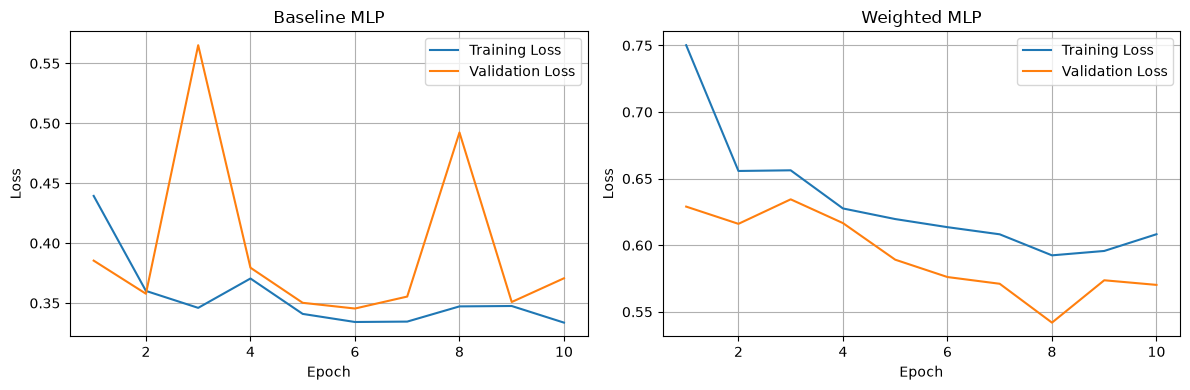

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

epochs = range(1, 11)

# Baseline MLP
axes[0].plot(epochs, baseline_train_losses, label="Training Loss")
axes[0].plot(epochs, baseline_val_losses, label="Validation Loss")
axes[0].set_title("Baseline MLP")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Weighted MLP
axes[1].plot(epochs, weighted_train_losses, label="Training Loss")
axes[1].plot(epochs, weighted_val_losses, label="Validation Loss")
axes[1].set_title("Weighted MLP")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### 6.5 Final Evaluation of Weighted MLP on Held-Out Test Set

After comparing the baseline and weighted MLP using validation results,
the weighted MLP was selected for final evaluation.

The held-out test dataset was not used during training or model selection. It is used here to assess how well the selected model generalises to unseen images. 

In [81]:
# Final evaluation on held-out test dataset
model.eval()
test_predictions = []
test_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)
        test_predictions.extend(predictions.tolist())
        test_labels.extend(labels.tolist())

# Confusion matrix
cm_test = confusion_matrix(test_labels, test_predictions, labels=[0, 1])
print(f"Test Confusion Matrix: {cm_test}")

# Evaluation metrics
test_accuracy = accuracy_score(test_labels, test_predictions)
test_precision = precision_score(test_labels, test_predictions, zero_division=0)
test_recall = recall_score(test_labels, test_predictions, zero_division=0)
test_f1 = f1_score(test_labels, test_predictions, zero_division=0)
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")
print(f"F1: {test_f1:.4f}")

Test Confusion Matrix: [[122 207]
 [ 24 126]]
Accuracy: 0.5177
Precision: 0.3784
Recall: 0.8400
F1: 0.5217


## 07. Discussion

### 7.1 Baseline MLP

The baseline MLP achieved an accuracy of 87.55%, but its performance in detecting effusion was poor. The model predicted all but 1 of validation images as "No Finding", resulting in zero recall for the Effusion class.

This demonstrates how accuracy can be misleading when working with imbalanced datasets. Although the model achieved relatively high accuracy, it failed to identify any of the minority-class Effusion images.

### 7.2 Weighted MLP

To address class imbalance, a second MLP was trained using class-weighted cross-entropy loss, assigning a higher penalty to incorrect predictions of the minority Effusion class.

The weighted MLP achieved an accuracy of 72.02%, precision of 28.78%, recall of 86.76%, and F1-score of 43.22% on the validation set. 

Compared to the baseline, the weighted MLP substantially improved Effusion detection, identifying 59 out of 68 actual Effusion images. However, this came at the cost of increased false positives, with 146 No Finding images incorrectly classified as Effusion.

This experiment demonstrated the trade-off between precision and recall, and how class weighting can influence a model's classification behaviour. 

### 7.3 Performance on test dataset

| Metric | Validation | Test |
| ------ | ---------- | ---- |
| Accuracy | 72.02% | 51.77% |
| Precision | 28.78% | 37.84% |
| Recall | 86.76% | 84.00% |
| F1 | 43.22% | 52.17% |

The recall score is consistent, scoring approximately 85% -- the model identifies approximately 8.5 out of 10 Effusion images in both datasets. 

Precision improves on the test set, with 4 out of 10 images predicted as Effusion actually having the Effusion label. The remaining predictions are false positives. 

However, accuracy on the test set is relatively low, incorrectly identifying 207 No Finding images as Effusion.

### 7.4 Limitations

The following limitations should be considered:
1. The dataset was imbalanced, with significantly fewer Effusion images than No Finding images.
2. The images were sized to 64x64, losing image detail.
3. MLP flattened image pixels into a 1-D vector without learning spatial relationships between pixels.
4. Experiments were limited to a simple MLP architecture and a binary classification task.

## 08.  Conclusion

This project provided practical experience in building and training a neural network using native PyTorch, including data preparation, model architecture, training and validation loops, and performance evaluation. 

The experiments demonstrated the limitations of relying on accuracy alone when evaluating imbalanced medical image datasets. They also provided an introduction to class weighting as a technique for improving minority-class detection, a common challenge in medical imaging. 

Although an MLP is limited in its ability to learn spatial features from medical images, the project established a foundation for exploring convolutional neural networks (CNNs), which are better suited to image-based feature extraction.

The next project will explore CNN-based classification and more advanced image recognition techniques.